In [2]:
import mdtraj as md

top = md.load_topology("/Users/Ritwik/Desktop/Projects/graph_analysis/analysis/rmsd_rmsf/WT/frame0.gro")
ca = top.select("protein and name CA")
print(len(ca), top.n_residues)

219 25703


In [11]:
import os, time
import mdtraj as md
import numpy as np

ROOT = "/Users/Ritwik/Desktop/Projects/graph_analysis"

# VARIANTS = {
#     "WT":    {"top": "analysis/rmsd_rmsf/WT/frame0.gro",
#               "traj": "data/raw/WT/WT_md_fit.xtc"},
#     "S99N":  {"top": "analysis/rmsd_rmsf/S99N/frame0.gro",
#               "traj": "data/raw/S99N/md_fit.xtc"},
#     "I155L": {"top": "analysis/rmsd_rmsf/I155L/frame0.gro",
#               "traj": "data/raw/I155L/md_fit.xtc"},
# }
VARIANTS = {
    "WT": {"top": "analysis/rmsd_rmsf/WT/frame0.gro",
           "traj": "data/raw/WT/WT_md_fit.xtc"},
}

OUTDIR = f"{ROOT}/analysis/networks"
os.makedirs(OUTDIR, exist_ok=True)

def extract_ca(variant, paths, force=False):
    xyz_out = f"{OUTDIR}/{variant}_ca_xyz.npy"
    res_out = f"{OUTDIR}/{variant}_resnums.npy"

    if os.path.exists(xyz_out) and not force:
        xyz = np.load(xyz_out)
        resnums = np.load(res_out)
        print(f"{variant}: cached  {xyz.shape}")
        return xyz, resnums

    top_path  = f"{ROOT}/{paths['top']}"
    traj_path = f"{ROOT}/{paths['traj']}"
    for p in (top_path, traj_path):
        if not os.path.exists(p):
            raise FileNotFoundError(f"{variant}: missing {p}  (HDD mounted?)")

    top = md.load_topology(top_path)
    ca_indices = top.select("protein and name CA")
    if len(ca_indices) != 219:
        raise ValueError(f"{variant}: got {len(ca_indices)} CA, expected 219")
    resnums = np.array([top.atom(i).residue.resSeq for i in ca_indices])

    t0 = time.time()
    chunks = []
    for chunk in md.iterload(traj_path, chunk=2000, top=top,
                             atom_indices=ca_indices):
        chunks.append(chunk.xyz)
        print(f"  {variant}: {sum(c.shape[0] for c in chunks)} frames",
              end="\r", flush=True)
    xyz = np.concatenate(chunks).astype(np.float32)

    np.save(xyz_out, xyz)
    np.save(res_out, resnums)
    print(f"\n{variant}: {xyz.shape}  resSeq {resnums[0]}–{resnums[-1]}  "
          f"{time.time()-t0:.0f}s")
    return xyz, resnums

data = {}
for v, paths in VARIANTS.items():
    data[v] = extract_ca(v, paths)

for v, (xyz, resnums) in data.items():
    print(v, xyz.shape, xyz.dtype, f"{xyz.nbytes/1e6:.0f} MB")

  WT: 50001 frames
WT: (50001, 219, 3)  resSeq 1–219  137s
WT (50001, 219, 3) float32 131 MB


In [12]:
xyz, resnums = data["WT"]
W = 5000
windows = [xyz[i*W:(i+1)*W] for i in range(10)]
print(len(windows), windows[0].shape, windows[-1].shape)

10 (5000, 219, 3) (5000, 219, 3)


In [13]:
import networkx as nx

def build_occupancy_graph(xyz, resnums, cutoff_lo=4.0, cutoff_hi=8.0,
                          min_occ=0.75, min_sep=2):
    xyz_ang = xyz * 10.0                      # nm -> Å
    n_frames, n_res, _ = xyz_ang.shape

    # sequence-separation mask: keep only |i-j| > min_sep
    idx = np.arange(n_res)
    sep_ok = np.abs(np.subtract.outer(idx, idx)) > min_sep

    counts = np.zeros((n_res, n_res))
    for frame in xyz_ang:
        d = np.linalg.norm(frame[:, None, :] - frame[None, :, :], axis=-1)
        counts += (d >= cutoff_lo) & (d <= cutoff_hi) & sep_ok

    occupancy = counts / n_frames

    G = nx.Graph()
    G.add_nodes_from(resnums)
    iu = np.triu_indices(n_res, k=1)           # upper triangle only
    for i, j in zip(*iu):
        if occupancy[i, j] >= min_occ:
            G.add_edge(resnums[i], resnums[j], weight=float(occupancy[i, j]))
    return G, occupancy

In [14]:
import time
t0 = time.time()
G1, occ1 = build_occupancy_graph(windows[0], resnums)
print(f"{G1.number_of_nodes()} nodes, {G1.number_of_edges()} edges, "
      f"{time.time()-t0:.0f}s")
print("connected:", nx.is_connected(G1))
print("mean degree:", 2*G1.number_of_edges()/G1.number_of_nodes())

219 nodes, 461 edges, 6s
connected: False
mean degree: 4.210045662100456


In [15]:
comps = sorted(nx.connected_components(G1), key=len, reverse=True)
print([len(c) for c in comps])
print([sorted(c) for c in comps[1:]])

[189, 4, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[[np.int64(80), np.int64(83), np.int64(84), np.int64(86)], [np.int64(15), np.int64(18)], [np.int64(13)], [np.int64(14)], [np.int64(16)], [np.int64(17)], [np.int64(19)], [np.int64(20)], [np.int64(21)], [np.int64(22)], [np.int64(23)], [np.int64(24)], [np.int64(77)], [np.int64(79)], [np.int64(82)], [np.int64(85)], [np.int64(87)], [np.int64(88)], [np.int64(106)], [np.int64(111)], [np.int64(121)], [np.int64(125)], [np.int64(128)], [np.int64(129)], [np.int64(130)], [np.int64(190)]]


In [17]:
import numpy as np, networkx as nx, os, pickle

ROOT = "/Users/Ritwik/Desktop/Projects/graph_analysis"
OUTDIR = f"{ROOT}/analysis/networks"
os.makedirs(OUTDIR, exist_ok=True)

RIDGE = [48, 52, 95, 137, 139, 140, 160, 164, 165, 168, 169]
MUT_SITES = [99, 155]

CUTOFF_LO, CUTOFF_HI, MIN_SEP = 4.0, 8.0, 2
THR = 0.50          # chosen from the window-1 scan: mid-plateau, no cliff
W = 5000            # frames per 100 ns window (20 ps timestep)
N_WINDOWS = 10

# ---------- occupancy matrix for one window ----------
def occupancy_matrix(xyz, cutoff_lo=CUTOFF_LO, cutoff_hi=CUTOFF_HI,
                     min_sep=MIN_SEP):
    xyz_ang = xyz * 10.0                      # nm -> Å
    n_frames, n_res, _ = xyz_ang.shape
    idx = np.arange(n_res)
    sep_ok = np.abs(np.subtract.outer(idx, idx)) > min_sep   # drop |i-j| <= 2
    counts = np.zeros((n_res, n_res))
    for frame in xyz_ang:
        d = np.linalg.norm(frame[:, None, :] - frame[None, :, :], axis=-1)
        counts += (d >= cutoff_lo) & (d <= cutoff_hi) & sep_ok
    return counts / n_frames

# ---------- weighted graph from an occupancy matrix ----------
def graph_from_occ(occ, resnums, thr=THR):
    G = nx.Graph()
    G.add_nodes_from(int(r) for r in resnums)
    for i, j in zip(*np.triu_indices(len(resnums), k=1)):
        if occ[i, j] >= thr:
            G.add_edge(int(resnums[i]), int(resnums[j]),
                       weight=float(occ[i, j]))
    return G

# ---------- build all windows for one variant ----------
def build_variant(variant, xyz, resnums, thr=THR, n_windows=N_WINDOWS, w=W):
    windows = [xyz[i*w:(i+1)*w] for i in range(n_windows)]
    graphs, occs, iso_sets = {}, {}, {}

    for k, win in enumerate(windows, start=1):
        occ = occupancy_matrix(win)
        G = graph_from_occ(occ, resnums, thr)
        graphs[k], occs[k] = G, occ
        iso_sets[k] = set(int(n) for n in nx.isolates(G))
        giant = len(max(nx.connected_components(G), key=len))
        ridge_in = sum(1 for r in RIDGE if G.degree(r) > 0)
        mut_in = sum(1 for r in MUT_SITES if G.degree(r) > 0)
        print(f"  window {k:02d}: {G.number_of_edges():4d} edges, "
              f"giant {giant:3d}/219, <k>={2*G.number_of_edges()/219:.2f}, "
              f"iso {len(iso_sets[k]):2d}, ridge {ridge_in:2d}/11, "
              f"mut {mut_in}/2")

    always = set.intersection(*iso_sets.values())
    ever   = set.union(*iso_sets.values())
    print(f"\n  isolated in ALL windows ({len(always)}): {sorted(always)}")
    print(f"  isolated in SOME window ({len(ever)}): {sorted(ever - always)}")

    out = f"{OUTDIR}/{variant}_occupancy_graphs.pkl"
    with open(out, "wb") as f:
        pickle.dump({"variant": variant, "graphs": graphs, "occupancy": occs,
                     "resnums": resnums, "threshold": thr,
                     "params": {"cutoff_lo": CUTOFF_LO, "cutoff_hi": CUTOFF_HI,
                                "min_sep": MIN_SEP, "frames_per_window": w}}, f)
    print(f"  saved -> {out}")
    return graphs, occs

# ---------- run: WT only ----------
xyz, resnums = data["WT"]
print(f"WT  thr={THR}  {N_WINDOWS} windows x {W} frames")
wt_graphs, wt_occs = build_variant("WT", xyz, resnums)

WT  thr=0.5  10 windows x 5000 frames
  window 01:  511 edges, giant 197/219, <k>=4.67, iso 15, ridge 11/11, mut 2/2
  window 02:  519 edges, giant 208/219, <k>=4.74, iso 11, ridge 11/11, mut 2/2
  window 03:  530 edges, giant 211/219, <k>=4.84, iso  6, ridge 11/11, mut 2/2
  window 04:  530 edges, giant 211/219, <k>=4.84, iso  6, ridge 11/11, mut 2/2
  window 05:  545 edges, giant 215/219, <k>=4.98, iso  4, ridge 11/11, mut 2/2
  window 06:  557 edges, giant 212/219, <k>=5.09, iso  5, ridge 11/11, mut 2/2
  window 07:  537 edges, giant 206/219, <k>=4.90, iso 11, ridge 11/11, mut 2/2
  window 08:  548 edges, giant 209/219, <k>=5.00, iso  4, ridge 11/11, mut 2/2
  window 09:  548 edges, giant 212/219, <k>=5.00, iso  7, ridge 11/11, mut 2/2
  window 10:  544 edges, giant 212/219, <k>=4.97, iso  5, ridge 11/11, mut 2/2

  isolated in ALL windows (2): [16, 106]
  isolated in SOME window (25): [13, 14, 17, 19, 20, 21, 22, 23, 39, 42, 77, 79, 80, 83, 84, 85, 86, 87, 88, 121, 125, 128, 130]
 

In [18]:
# ---------- DCCM for one window ----------
def dccm_matrix(xyz):
    dr = xyz - xyz.mean(axis=0)                      # (n_frames, n_res, 3)
    dot = np.einsum("tik,tjk->ij", dr, dr)
    var = np.diagonal(dot)
    return dot / np.sqrt(np.outer(var, var))         # in [-1, 1]

# ---------- scan: how dense is the DCCM graph at various cutoffs ----------
xyz, resnums = data["WT"]
windows = [xyz[i*W:(i+1)*W] for i in range(N_WINDOWS)]

corr5 = dccm_matrix(windows[4])                      # window 5, post-equilibration
n_res = len(resnums)
idx = np.arange(n_res)
sep_ok = np.abs(np.subtract.outer(idx, idx)) > MIN_SEP
possible = sep_ok[np.triu_indices(n_res, k=1)].sum()

print(f"possible pairs (|i-j|>2): {possible}")
print(f"{'cutoff':>7} {'edges':>7} {'density':>8} {'<k>':>6}")
for c in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
    A = (np.abs(corr5) >= c) & sep_ok
    e = A[np.triu_indices(n_res, k=1)].sum()
    print(f"{c:>7.1f} {e:>7d} {e/possible:>8.3f} {2*e/n_res:>6.1f}")

possible pairs (|i-j|>2): 23436
 cutoff   edges  density    <k>
    0.3    3823    0.163   34.9
    0.4    1598    0.068   14.6
    0.5     659    0.028    6.0
    0.6     302    0.013    2.8
    0.7      92    0.004    0.8
    0.8      14    0.001    0.1


In [19]:
DCCM_CUTOFFS = {"loose": 0.3, "tight": 0.5}

def dccm_graph(corr, resnums, cutoff, sep_ok):
    G = nx.Graph()
    G.add_nodes_from(int(r) for r in resnums)
    iu = np.triu_indices(len(resnums), k=1)
    for i, j in zip(*iu):
        if sep_ok[i, j] and abs(corr[i, j]) >= cutoff:
            G.add_edge(int(resnums[i]), int(resnums[j]),
                       weight=float(abs(corr[i, j])),
                       correlation=float(corr[i, j]))
    return G

dccm_graphs, dccm_mats = {}, {}
for k, win in enumerate(windows, start=1):
    corr = dccm_matrix(win)
    dccm_mats[k] = corr
    dccm_graphs[k] = {}
    line = f"  window {k:02d}:"
    for name, c in DCCM_CUTOFFS.items():
        G = dccm_graph(corr, resnums, c, sep_ok)
        dccm_graphs[k][name] = G
        neg = sum(1 for _, _, d in G.edges(data=True) if d["correlation"] < 0)
        line += (f"  {name} {G.number_of_edges():5d} edges "
                 f"<k>={2*G.number_of_edges()/n_res:5.1f} neg={neg:4d}")
    print(line)

with open(f"{OUTDIR}/WT_dccm_graphs.pkl", "wb") as f:
    pickle.dump({"variant": "WT", "graphs": dccm_graphs, "matrices": dccm_mats,
                 "resnums": resnums, "cutoffs": DCCM_CUTOFFS,
                 "min_sep": MIN_SEP}, f)
print(f"\nsaved -> {OUTDIR}/WT_dccm_graphs.pkl")

  window 01:  loose  4103 edges <k>= 37.5 neg=1011  tight   965 edges <k>=  8.8 neg= 109
  window 02:  loose  4727 edges <k>= 43.2 neg=1446  tight  1177 edges <k>= 10.7 neg= 225
  window 03:  loose  2320 edges <k>= 21.2 neg= 579  tight   500 edges <k>=  4.6 neg=  22
  window 04:  loose  4662 edges <k>= 42.6 neg=1531  tight  1114 edges <k>= 10.2 neg= 235
  window 05:  loose  3823 edges <k>= 34.9 neg=1793  tight   659 edges <k>=  6.0 neg=  88
  window 06:  loose  3161 edges <k>= 28.9 neg=1345  tight   482 edges <k>=  4.4 neg=  20
  window 07:  loose  4714 edges <k>= 43.1 neg=2171  tight  1006 edges <k>=  9.2 neg= 239
  window 08:  loose  5470 edges <k>= 50.0 neg=2847  tight   949 edges <k>=  8.7 neg= 211
  window 09:  loose  2494 edges <k>= 22.8 neg= 965  tight   446 edges <k>=  4.1 neg=   5
  window 10:  loose  2430 edges <k>= 22.2 neg= 804  tight   454 edges <k>=  4.1 neg=   0

saved -> /Users/Ritwik/Desktop/Projects/graph_analysis/analysis/networks/WT_dccm_graphs.pkl


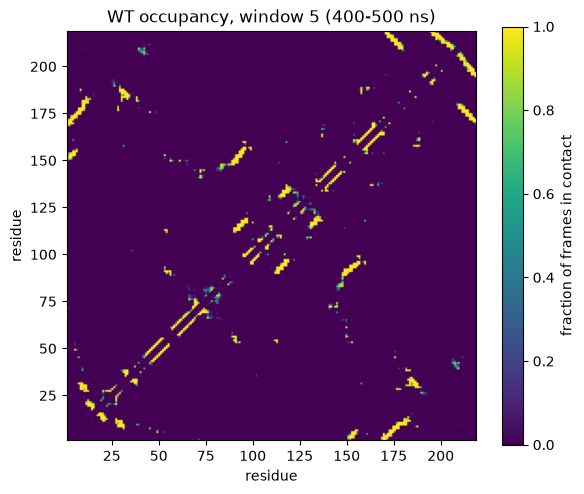

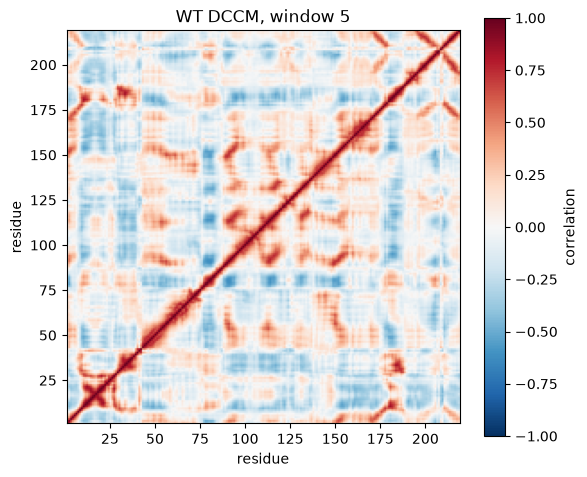

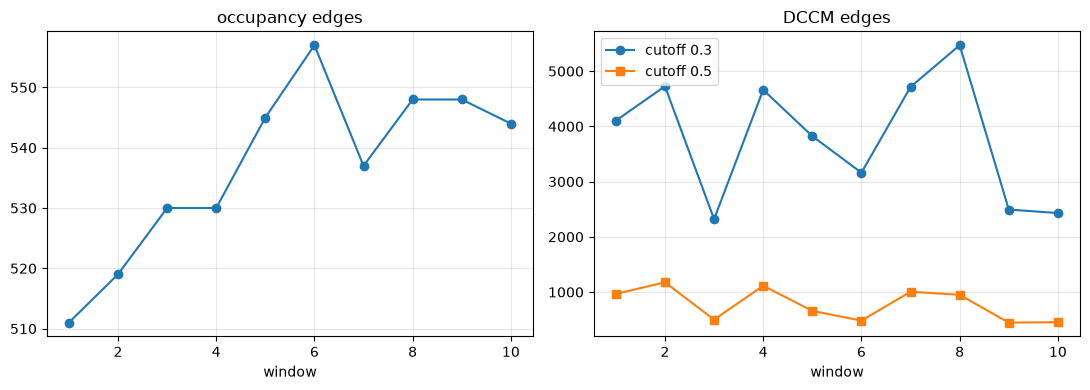

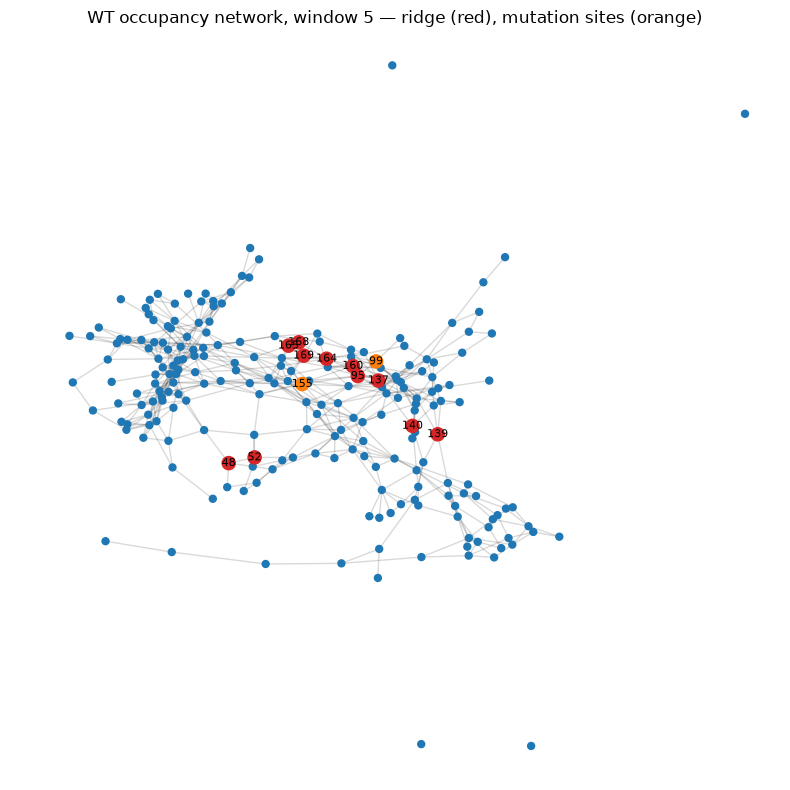

In [20]:
import matplotlib.pyplot as plt

FIGDIR = f"{ROOT}/figures"
os.makedirs(FIGDIR, exist_ok=True)

# ---- 1. occupancy matrix, window 5 ----
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(wt_occs[5], cmap="viridis", origin="lower",
               extent=[1, 219, 1, 219])
ax.set_xlabel("residue"); ax.set_ylabel("residue")
ax.set_title("WT occupancy, window 5 (400-500 ns)")
plt.colorbar(im, label="fraction of frames in contact")
plt.tight_layout(); plt.savefig(f"{FIGDIR}/WT_occ_w05.png", dpi=150); plt.show()

# ---- 2. DCCM, window 5 ----
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(dccm_mats[5], cmap="RdBu_r", vmin=-1, vmax=1,
               origin="lower", extent=[1, 219, 1, 219])
ax.set_xlabel("residue"); ax.set_ylabel("residue")
ax.set_title("WT DCCM, window 5")
plt.colorbar(im, label="correlation")
plt.tight_layout(); plt.savefig(f"{FIGDIR}/WT_dccm_w05.png", dpi=150); plt.show()

# ---- 3. occupancy vs DCCM stability across windows ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ws = range(1, 11)
ax[0].plot(ws, [wt_graphs[k].number_of_edges() for k in ws], "o-")
ax[0].set_title("occupancy edges"); ax[0].set_xlabel("window")
ax[1].plot(ws, [dccm_graphs[k]["loose"].number_of_edges() for k in ws],
           "o-", label="cutoff 0.3")
ax[1].plot(ws, [dccm_graphs[k]["tight"].number_of_edges() for k in ws],
           "s-", label="cutoff 0.5")
ax[1].set_title("DCCM edges"); ax[1].set_xlabel("window"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIGDIR}/WT_edge_stability.png", dpi=150); plt.show()

# ---- 4. the network itself, window 5, ridge highlighted ----
G = wt_graphs[5]
pos = nx.spring_layout(G, seed=42, weight="weight")
colors = ["#d62728" if n in RIDGE else
          "#ff7f0e" if n in MUT_SITES else "#1f77b4" for n in G.nodes()]
sizes = [90 if n in RIDGE or n in MUT_SITES else 25 for n in G.nodes()]
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, alpha=0.15, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: n for n in RIDGE + MUT_SITES},
                        font_size=8, ax=ax)
ax.set_title("WT occupancy network, window 5 — ridge (red), mutation sites (orange)")
ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGDIR}/WT_network_w05.png", dpi=150); plt.show()